# Lab01 · КТвД · доп. задание: пропорции шрифтов

**Две случайные величины одной природы: высота строчных (x-height) и толщина основного штриха.**

| | |
|---|---|
| Датасет | собственный: шрифты Google Fonts, измерены по контурам букв скриптом `labfont` (fontTools) |
| Генеральная совокупность | собранная коллекция, $N = 33$ семейств; одно начертание на семейство, ближайшее к Regular |
| Категории | serif 13, sans 12, handwriting 4, display 3, mono 1 |
| Случайные величины | RV01 **x-height**, RV02 **толщина штриха «l»**; обе в долях кегля |
| Автор | Быкова Кристина Денисовна (ИСУ 501322), трек КТвД |
| Код | `labfont/` (измерения, схема), `labstat/` (статистика, общая с основной частью), тесты `tests/test_labfont.py` |

<a id="toc"></a>
**Содержание**

- [1. Dataset: коллекция шрифтов](#ds)
    - [1.1 Как измерено](#ds-how)
    - [1.2 Обзор данных](#ds-eda)
- [2. Random Variable 01 (x-height)](#rv1)
    - [2.1 Description (природа события)](#rv1-desc)
    - [2.2 EDA & Distribution](#rv1-eda)
- [3. Random Variable 02 (толщина штриха)](#rv2)
    - [3.1 Description (природа события)](#rv2-desc)
    - [3.2 EDA & Distribution](#rv2-eda)
- [4. Independence: x-height и толщина штриха](#dep)
    - [4.1 Гипотеза: у гротесков x-height больше, чем у антикв](#hyp)
- [5. Resume](#resume)
    - [5.1 Итоговые метрики](#res-metrics)
    - [5.2 Выводы](#res-concl)
    - [5.3 Литература](#res-lit)
    - [5.4 cat_mark_table](#res-marks)

*Код в ячейках скрыт; раскрыть — щелчок по полоске слева от ячейки. Основная часть работы: [`../lab01.ipynb`](../lab01.ipynb).*

In [1]:
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats
import sys; sys.path.insert(0, "..")   # пакеты labstat и labfont лежат в корне репозитория

from labstat import dependence, describe as dsc, distributions as dist, hypotheses as hyp, stochastic, plots
from labfont import fontplots as fp
from labfont.illustrate import measurement_figure

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 4)
plots.style()
SEED = 2026
raw = pd.read_csv("../data/fonts.csv")
raw["category"] = raw["category"].fillna("")
# Шрифты без настоящих строчных (капитель SC, униказ): их «x» — это капитель или прописная
print("Исключены (нет строчных букв):", raw.family[raw.no_lowercase].tolist())
fonts = raw[~raw.no_lowercase].reset_index(drop=True)
OTHERS = ['cap_height', 'contrast', 'width_o', 'adv_mean', 'weight_class']
fonts.shape

Исключены (нет строчных букв): ['Alegreya SC', 'Cormorant SC', 'Rubik Mono One', 'Spectral SC']


(33, 20)

<a id="ds"></a>
## 1. Dataset: коллекция шрифтов

<a id="ds-how"></a>
### 1.1 Как измерено

Каждое семейство скачано с fonts.google.com («Get font → Download all») и разложено по папкам категорий.
Скрипт `python -m labfont.collect fonts/ data/fonts.csv` берёт из архива одно начертание, ближайшее к Regular
(прямое, вес 400; у вариативного шрифта создаётся экземпляр с $\mathrm{wght} = 400$), и меряет контуры букв.

Все длины делятся на размер кегля в единицах шрифта (UPM), поэтому величины **безразмерные, в долях кегля**:
x-height $= 0.5$ значит, что при кегле 16 px строчные буквы высотой 8 px.

- **x-height**: верхняя точка контура «x»;
- **толщина штриха**: ширина вертикали «l» на линии $y = \tfrac12\,$x-height. Контур дробится в многоугольник,
  точки пересечения с горизонталью сортируются, между парами лежит «чернила» (правило чёт-нечет);
- **контраст**: толщина боков «o» к толщине верха и низа; **ширина**: ширина «o» к x-height.

**Очистка.** Измерено 37 семейств. Исключены 4 шрифта без настоящих строчных букв
(Alegreya SC, Cormorant SC, Rubik Mono One, Spectral SC): в капительных (SC) и униказовых шрифтах на месте «x» стоит капитель или прописная,
и «x-height» у них — это не высота строчных. Spectral SC вдобавок повторяет Spectral. Начертания оптических размеров
(Inter 18pt, Fraunces 72pt) и ширин (Roboto SemiCondensed) объединены с основным семейством по папке Google Fonts.
Категории взяты из каталога fonts.google.com (`data/font_categories.csv`).

Почему одно начертание на семейство: Bold, Italic и Regular одного семейства рисовал один дизайнер,
это зависимые наблюдения. Наблюдение здесь — семейство.


<sub>[↑ к содержанию](#toc)</sub>

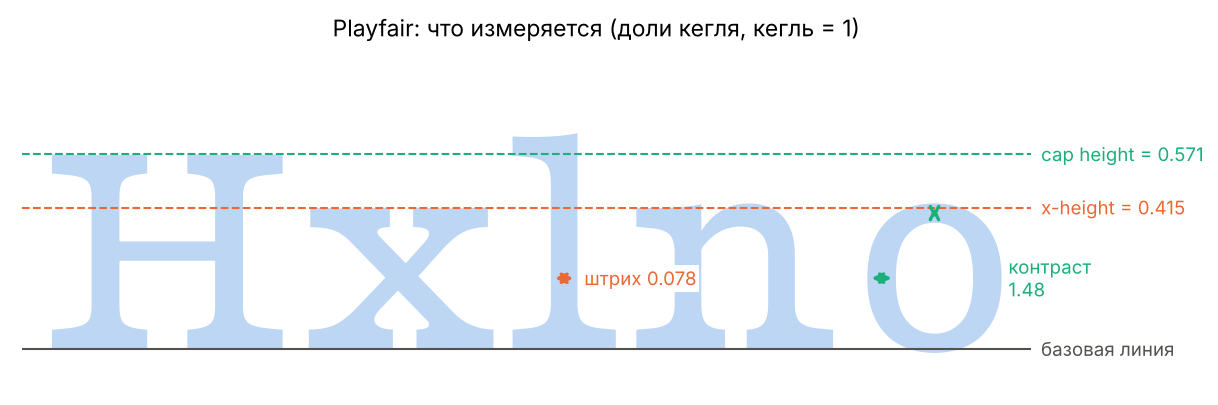

In [2]:
fig, m = measurement_figure(Path("../data/fonts_sample/Playfair-VariableFont.ttf").read_bytes())
plots.save(fig, "fonts_measure.png");

<a id="fig1"></a>
*Рис. 1. Схема измерений на контурах настоящего шрифта: x-height, высота прописных, толщина штриха «l» и контраст «o».*

<a id="ds-eda"></a>
### 1.2 Обзор данных


<sub>[↑ к содержанию](#toc)</sub>

In [3]:
print("Семейств:", len(fonts), "| с кириллицей:", int(fonts.has_cyrillic.sum()), "| вариативных:", int(fonts.is_variable.sum()))
print("Вес OS/2 у выбранных начертаний:", fonts.weight_class.value_counts().sort_index().to_dict())
fonts.groupby("category")[["x_height", "stem", "contrast", "width_o"]].median().round(3)

Семейств: 33 | с кириллицей: 25 | вариативных: 16
Вес OS/2 у выбранных начертаний: {400: 33}


,x_height,stem,contrast,width_o
category,,,,
display,0.500,0.089,0.486,1.045
handwriting,0.500,0.062,1.065,0.830
mono,0.536,0.090,1.233,0.914
sans,0.527,0.087,1.176,0.921
serif,0.450,0.081,2.104,0.979


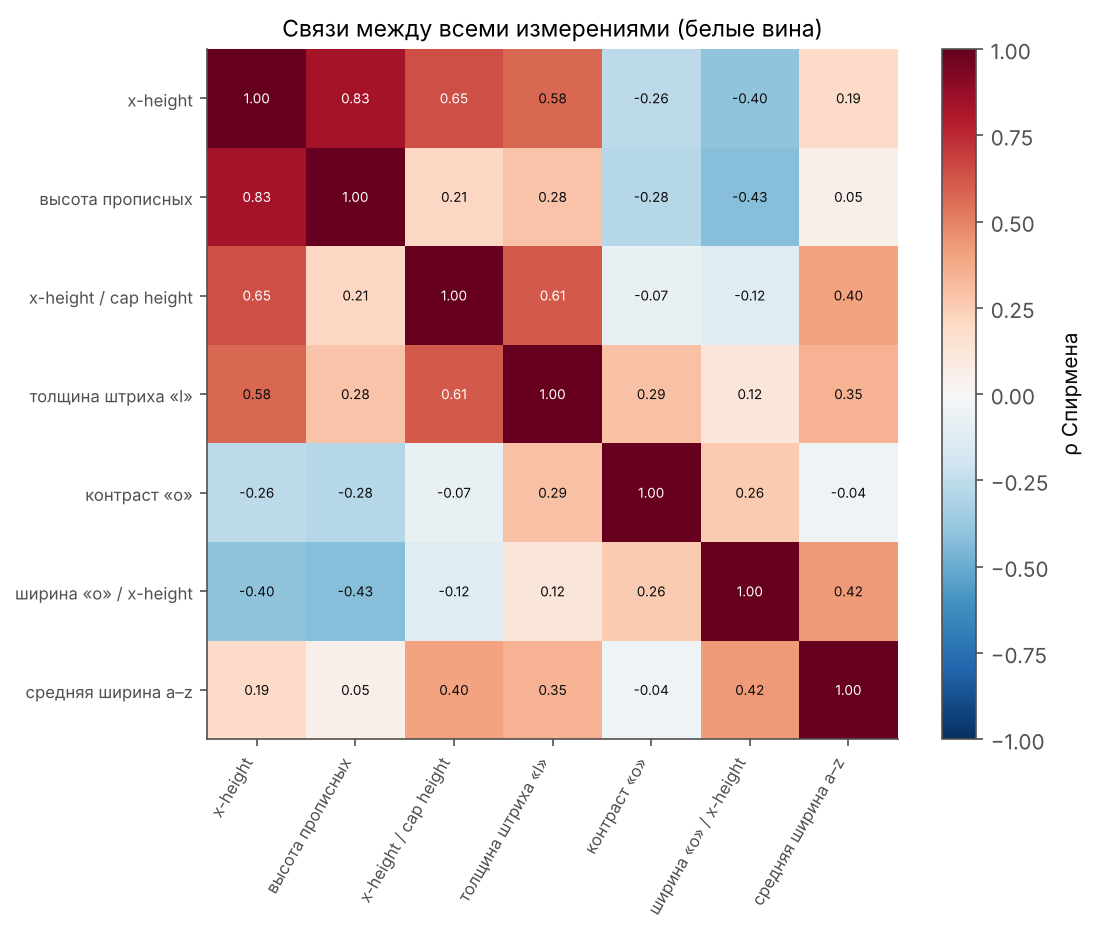

In [4]:
cols = ["x_height", "cap_height", "x_to_cap", "stem", "contrast", "width_o", "adv_mean"]
plots.corr_heatmap(fonts[cols].rename(columns=fp.COL_RU).corr(method="spearman"), "fonts_corr.png");

<a id="fig2"></a>
*Рис. 2. Ранговые корреляции Спирмена $\rho$ между измерениями шрифтов.*

<a id="rv1"></a>
## 2. Random Variable 01 (x-height)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv1-desc"></a>
### 2.1 Description (природа события)

**Величина.** Высота строчных в долях кегля; точность измерения $1/\mathrm{UPM}$ (у большинства шрифтов
$1/1000$ или $1/2048$ кегля), то есть $\le 0.001$.

**Событие.** Из коллекции случайно выбирается семейство шрифтов, у его Regular измеряется высота строчных.

**Что посчитано для проверки стохастической природы.** Прогноз величины по остальным измерениям
(высота прописных, контраст, ширина «o», средняя ширина букв, вес OS/2 и вторая величина) на 5-кратной кросс-валидации: линейная регрессия и $k = 5$ ближайших
соседей. Если бы величина вычислялась формулой из остальных, $R^2 \approx 1$, а остаток был бы порядка
точности $0.001$. Плюс разброс внутри одной категории: если бы категория (гротеск, антиква…) задавала величину,
внутри категории разброса бы не было.

**TODO КТвД: природа события своими словами.** _Вопросы: кто и почему выбирает x-height шрифта? можно ли его
вычислить по другим пропорциям или по категории? что из расчёта ниже говорит «за» и «против»?_


<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² = -2.599, СКО остатка 0.0937 кегля
5 ближайших соседей: R² = 0.330, СКО остатка 0.0422 кегля
Наблюдений в модели: 33 (без шрифтов с неизмеренным контрастом)
СКО самой величины 0.0521; точность измерения ≤ 0.001


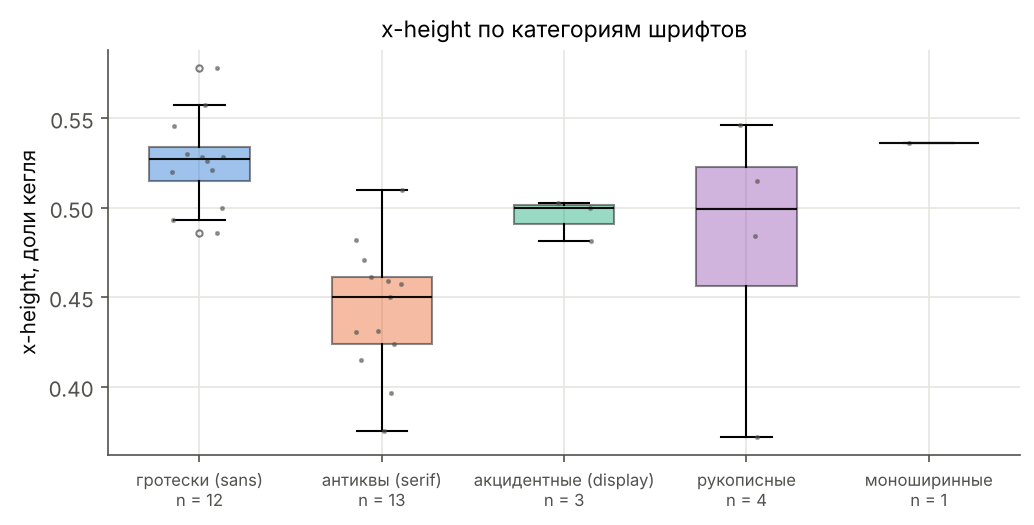

In [5]:
full = fonts.dropna(subset=OTHERS + ["x_height", "stem"])   # без шрифтов с неизмеренным контрастом
y = full["x_height"].to_numpy()
Xo = full[[c for c in OTHERS + ["x_height", "stem"] if c != "x_height"]].to_numpy()
lin = stochastic.cv_r2_linear(Xo, y, k=5, seed=SEED)
knn = stochastic.cv_r2_knn(Xo, y, k_neighbors=5, k=5, seed=SEED)
print(f"Линейная модель: R² = {lin['r2_cv']:.3f}, СКО остатка {lin['resid_std']:.4f} кегля")
print(f"5 ближайших соседей: R² = {knn['r2_cv']:.3f}, СКО остатка {knn['resid_std']:.4f} кегля")
print(f"Наблюдений в модели: {len(full)} (без шрифтов с неизмеренным контрастом)")
print(f"СКО самой величины {y.std(ddof=1):.4f}; точность измерения ≤ 0.001")
fp.box_by_category(fonts, "x_height", "x-height", "доли кегля", "fonts_x_height_by_cat.png");

<a id="fig_x_height_cat"></a>
*Рис. 3. x-height по категориям шрифтов: ящики с усами и сами наблюдения.*

**Результаты:**

- Линейная модель по остальным измерениям: $R^2 = -2.599$, СКО остатка 0.0937 кегля (отрицательный $R^2$ на кросс-валидации: прогноз на новых шрифтах хуже, чем просто среднее; 6 признаков при 33 наблюдениях, модель переобучается).
- 5 ближайших соседей: $R^2 = 0.330$, СКО остатка 0.0422 кегля.
- СКО самой величины 0.0521 (шрифтов в модели: 33), точность измерения $\le 0.001$: даже лучший остаток (0.0422) больше точности, отношение $\approx 42$.
- Средний по категориям разброс внутри категории составляет 72 % общего СКО.

<a id="rv1-eda"></a>
### 2.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [6]:
x_x_height = fonts["x_height"].to_numpy()
print("Выбросов по правилу 1.5·IQR:", dsc.iqr_outliers(x_x_height).sum())
display(dsc.compare_table({"все": x_x_height} | {c: g["x_height"] for c, g in fonts.groupby("category")}).T)
fit_x_height = dist.fit_candidates(x_x_height)
fit_x_height

Выбросов по правилу 1.5·IQR: 0


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
все,33.0,0.4852,0.0027,0.0521,0.1074,0.3720,0.4575,0.4933,0.5260,0.5780,0.0685,0.5000,-0.5126,-0.4398,31.0,0.0001
display,3.0,0.4947,0.0001,0.0115,0.0233,0.4814,0.4907,0.5000,0.5013,0.5026,0.0106,0.4814,-0.6669,-1.5000,3.0,0.0026
handwriting,4.0,0.4793,0.0058,0.0758,0.1583,0.3720,0.4560,0.4995,0.5228,0.5460,0.0668,0.3720,-0.7855,-0.9347,4.0,0.0310
mono,1.0,0.5360,NaN,NaN,NaN,0.5360,0.5360,0.5360,0.5360,0.5360,0.0000,0.5360,NaN,NaN,1.0,NaN
sans,12.0,0.5262,0.0007,0.0261,0.0496,0.4861,0.5150,0.5272,0.5340,0.5780,0.0190,0.5283,0.3109,-0.3280,11.0,0.0011
serif,13.0,0.4432,0.0013,0.0363,0.0820,0.3750,0.4238,0.4500,0.4610,0.5100,0.0372,0.3750,-0.1155,-0.4022,13.0,0.0003


,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
skewnorm,3,52.6299,-99.2597,-94.7702,0.0632,"(-3.6186, 0.5479, 0.081)"
weibull_min,3,52.4080,-98.8159,-94.3264,0.0713,"(10.5059, 0.0428, 0.4646)"
norm,2,51.1779,-98.3559,-95.3629,0.1068,"(0.4852, 0.0513)"
lognorm,3,51.1779,-96.3559,-91.8663,0.1068,"(0.0, -32767.628, 32768.1132)"
gamma,3,50.7963,-95.5925,-91.1030,0.1169,"(245.241, -0.3339, 0.0033)"


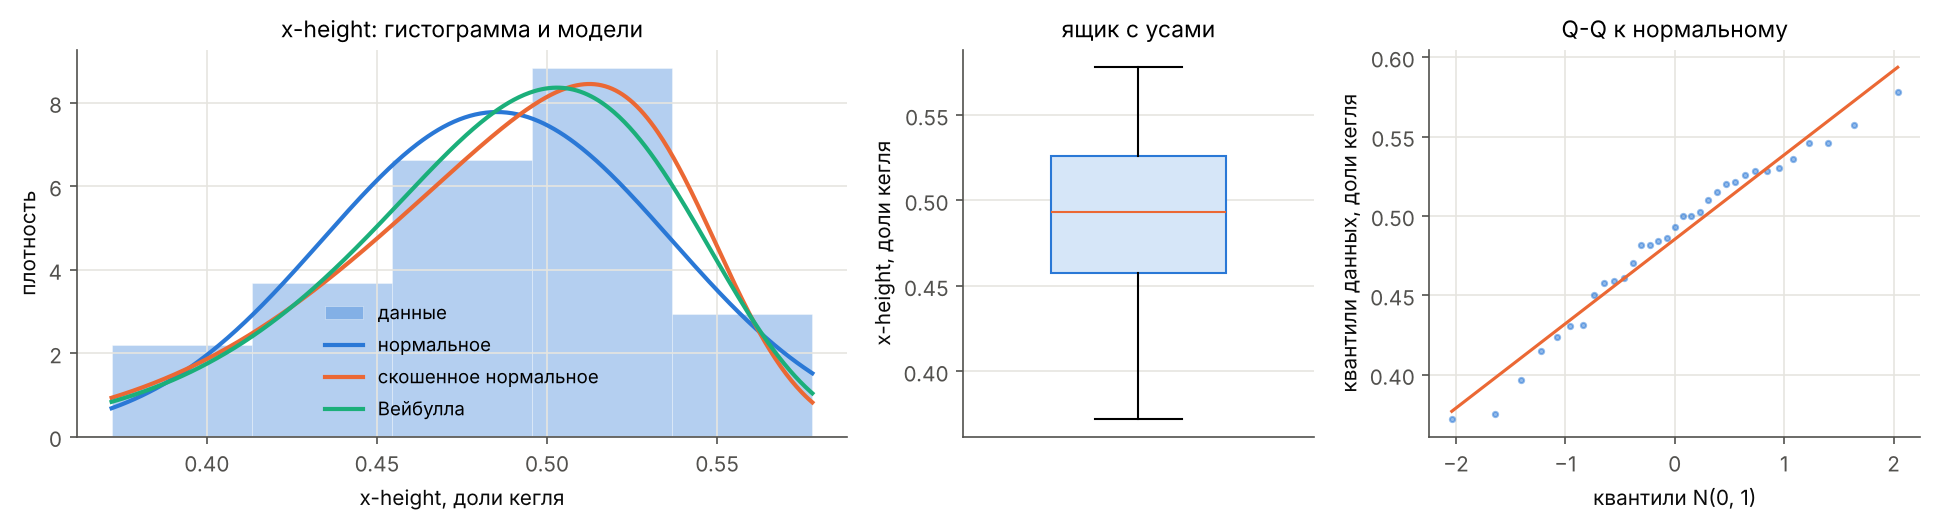

In [7]:
best_x_height = {nm: dist.fit(nm, x_x_height) for nm in ["norm"] + [d for d in fit_x_height.index if d != "norm"][:2]}
plots.eda_panel(x_x_height, "x-height", "доли кегля", best_x_height, "fonts_x_height_eda.png", bins="fd");

<a id="fig_x_height_eda"></a>
*Рис. 4. x-height: гистограмма с подобранными плотностями, ящик с усами, Q-Q к нормальному.*

**Результаты:**

- $N = 33$, среднее 0.485, медиана 0.493, СКО 0.0521, коэффициент вариации 10.7 %.
- Асимметрия $-0.51$, эксцесс $-0.44$; диапазон 0.372–0.578; выбросов по $1.5\cdot\mathrm{IQR}$: 0.
- Лучшее семейство по AIC: skewnorm; D'Agostino $K^2$ для нормального: $p = 0.393$.

**TODO КТвД: что видно на гистограмме и Q-Q, своими словами.**

<a id="rv2"></a>
## 3. Random Variable 02 (толщина штриха)

<sub>[↑ к содержанию](#toc)</sub>

<a id="rv2-desc"></a>
### 3.1 Description (природа события)

**Величина.** Толщина вертикали «l» в долях кегля; точность измерения $1/\mathrm{UPM}$ (у большинства шрифтов
$1/1000$ или $1/2048$ кегля), то есть $\le 0.001$.

**Событие.** Из коллекции случайно выбирается семейство шрифтов, у его Regular измеряется толщина вертикали «l».

**Что посчитано для проверки стохастической природы.** Прогноз величины по остальным измерениям
(высота прописных, контраст, ширина «o», средняя ширина букв, вес OS/2 и вторая величина) на 5-кратной кросс-валидации: линейная регрессия и $k = 5$ ближайших
соседей. Если бы величина вычислялась формулой из остальных, $R^2 \approx 1$, а остаток был бы порядка
точности $0.001$. Плюс разброс внутри одной категории: если бы категория (гротеск, антиква…) задавала величину,
внутри категории разброса бы не было.

**TODO КТвД: природа события своими словами.** _Вопросы: кто и почему выбирает толщина штриха шрифта? можно ли его
вычислить по другим пропорциям или по категории? что из расчёта ниже говорит «за» и «против»?_


<sub>[↑ к содержанию](#toc)</sub>

Линейная модель: R² = -0.445, СКО остатка 0.0479 кегля
5 ближайших соседей: R² = 0.024, СКО остатка 0.0400 кегля
Наблюдений в модели: 33 (без шрифтов с неизмеренным контрастом)
СКО самой величины 0.0412; точность измерения ≤ 0.001


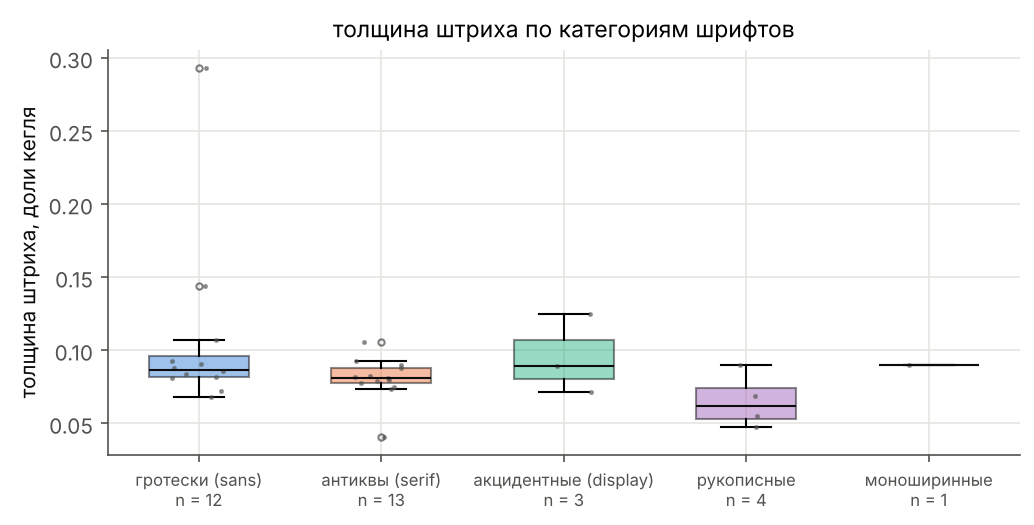

In [8]:
full = fonts.dropna(subset=OTHERS + ["x_height", "stem"])   # без шрифтов с неизмеренным контрастом
y = full["stem"].to_numpy()
Xo = full[[c for c in OTHERS + ["x_height", "stem"] if c != "stem"]].to_numpy()
lin = stochastic.cv_r2_linear(Xo, y, k=5, seed=SEED)
knn = stochastic.cv_r2_knn(Xo, y, k_neighbors=5, k=5, seed=SEED)
print(f"Линейная модель: R² = {lin['r2_cv']:.3f}, СКО остатка {lin['resid_std']:.4f} кегля")
print(f"5 ближайших соседей: R² = {knn['r2_cv']:.3f}, СКО остатка {knn['resid_std']:.4f} кегля")
print(f"Наблюдений в модели: {len(full)} (без шрифтов с неизмеренным контрастом)")
print(f"СКО самой величины {y.std(ddof=1):.4f}; точность измерения ≤ 0.001")
fp.box_by_category(fonts, "stem", "толщина штриха", "доли кегля", "fonts_stem_by_cat.png");

<a id="fig_stem_cat"></a>
*Рис. 5. Толщина штриха по категориям шрифтов: ящики с усами и сами наблюдения.*

**Результаты:**

- Линейная модель по остальным измерениям: $R^2 = -0.445$, СКО остатка 0.0479 кегля (отрицательный $R^2$ на кросс-валидации: прогноз на новых шрифтах хуже, чем просто среднее; 6 признаков при 33 наблюдениях, модель переобучается).
- 5 ближайших соседей: $R^2 = 0.024$, СКО остатка 0.0400 кегля.
- СКО самой величины 0.0412 (шрифтов в модели: 33), точность измерения $\le 0.001$: даже лучший остаток (0.0400) больше точности, отношение $\approx 40$.
- Средний по категориям разброс внутри категории составляет 74 % общего СКО.

<a id="rv2-eda"></a>
### 3.2 EDA & Distribution

<sub>[↑ к содержанию](#toc)</sub>

In [9]:
x_stem = fonts["stem"].to_numpy()
print("Выбросов по правилу 1.5·IQR:", dsc.iqr_outliers(x_stem).sum())
display(dsc.compare_table({"все": x_stem} | {c: g["stem"] for c, g in fonts.groupby("category")}).T)
fit_stem = dist.fit_candidates(x_stem)
fit_stem

Выбросов по правилу 1.5·IQR: 5


,n,mean,var,std,cv,min,q25,median,q75,max,iqr,mode,skew,kurt,n_unique,step
все,33.0,0.0901,0.0017,0.0412,0.4565,0.0410,0.0752,0.0825,0.0900,0.2931,0.0148,0.0879,3.7676,16.2853,31.0,5.7251e-05
display,3.0,0.0953,0.0007,0.0272,0.2860,0.0715,0.0804,0.0893,0.1071,0.1250,0.0267,0.0715,0.3848,-1.5000,3.0,1.7747e-02
handwriting,4.0,0.0654,0.0003,0.0186,0.2836,0.0475,0.0534,0.0622,0.0742,0.0899,0.0208,0.0475,0.4739,-1.2352,4.0,7.8627e-03
mono,1.0,0.0900,NaN,NaN,NaN,0.0900,0.0900,0.0900,0.0900,0.0900,0.0000,0.0900,NaN,NaN,1.0,NaN
sans,12.0,0.1074,0.0038,0.0617,0.5741,0.0680,0.0818,0.0869,0.0965,0.2931,0.0147,0.0680,2.5389,5.1985,12.0,1.1353e-03
serif,13.0,0.0806,0.0002,0.0147,0.1820,0.0410,0.0780,0.0811,0.0879,0.1058,0.0099,0.0410,-1.2049,2.6541,13.0,4.8828e-04


,k,loglik,AIC,BIC,KS_D,params
dist,,,,,,
lognorm,3,73.1538,-140.3076,-135.8181,0.2161,"(0.4277, 0.0218, 0.0617)"
gamma,3,71.2001,-136.4002,-131.9106,0.2389,"(3.129, 0.0346, 0.0177)"
skewnorm,3,67.7753,-129.5506,-125.0611,0.3233,"(4.3906, 0.0544, 0.0541)"
norm,2,58.9664,-113.9329,-110.9399,0.3204,"(0.0901, 0.0405)"
weibull_min,3,-inf,inf,inf,0.2023,"(0.7437, 0.068, 0.018)"


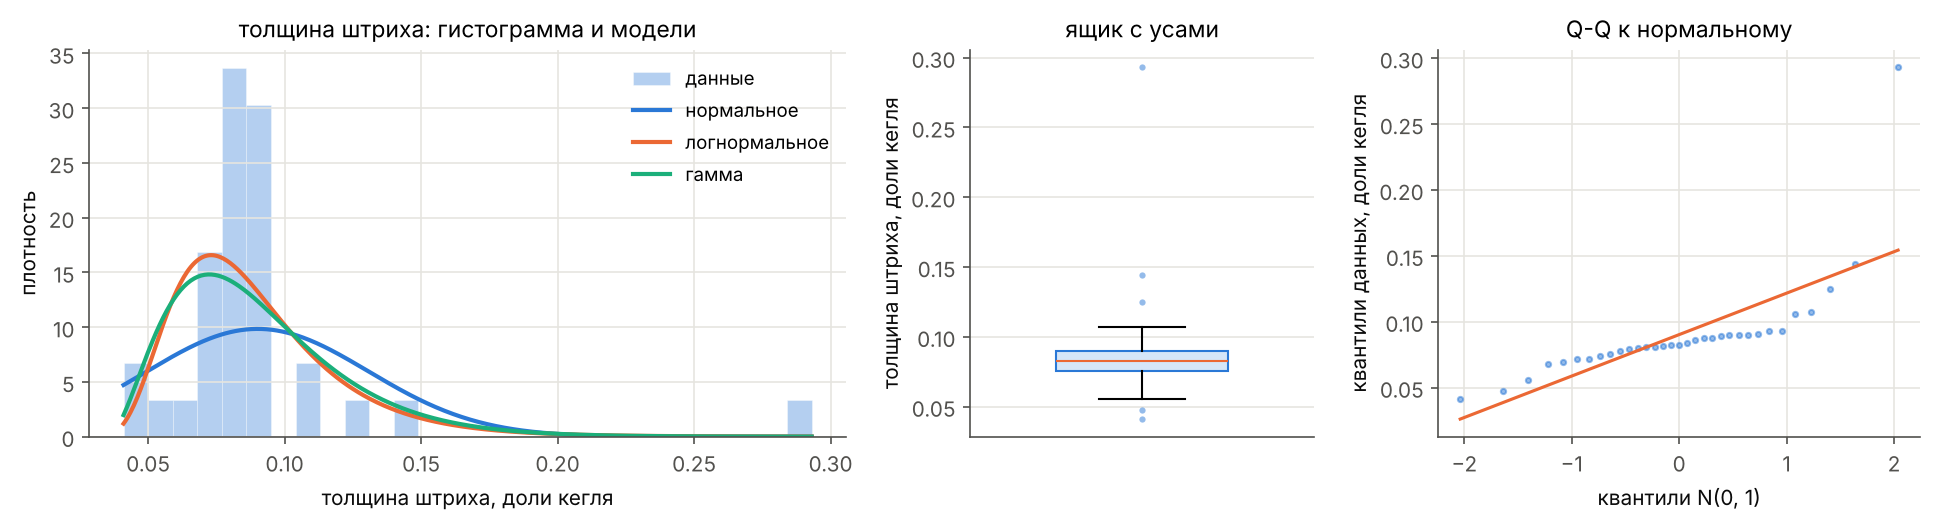

In [10]:
best_stem = {nm: dist.fit(nm, x_stem) for nm in ["norm"] + [d for d in fit_stem.index if d != "norm"][:2]}
plots.eda_panel(x_stem, "толщина штриха", "доли кегля", best_stem, "fonts_stem_eda.png", bins="fd");

<a id="fig_stem_eda"></a>
*Рис. 6. Толщина штриха: гистограмма с подобранными плотностями, ящик с усами, Q-Q к нормальному.*

**Результаты:**

- $N = 33$, среднее 0.090, медиана 0.083, СКО 0.0412, коэффициент вариации 45.7 %.
- Асимметрия $+3.77$, эксцесс $+16.29$; диапазон 0.041–0.293; выбросов по $1.5\cdot\mathrm{IQR}$: 5.
- Лучшее семейство по AIC: lognorm; D'Agostino $K^2$ для нормального: $p \approx 10^{-13}$.

**TODO КТвД: что видно на гистограмме и Q-Q, своими словами.**

<a id="dep"></a>
## 4. Independence: x-height и толщина штриха

Обе величины одной природы: пропорции одной и той же буквы, их задаёт один дизайнер. По условию для таких величин
проверяется независимость. $H_0$: x-height и толщина штриха независимы. Проверки: корреляции Пирсона, Спирмена,
Кендалла; $\chi^2$ на таблице сопряжённости по квантилям; перестановочный тест для $\rho$ Спирмена
(2000 перестановок). Отдельно $\rho$ внутри каждой категории: общая связь может возникать только из-за смеси
категорий (парадокс Симпсона).


<sub>[↑ к содержанию](#toc)</sub>

,coef,p
method,,
pearson,0.3741,0.0319
spearman,0.5761,0.0005
kendall,0.4183,0.0006


χ² = 10.9, df = 1, p = 0.000949, V Крамера = 0.575
перестановочный тест: ρ = 0.576, p = 0.0010
ρ внутри категорий: {'sans': np.float64(0.581), 'serif': np.float64(0.918)}


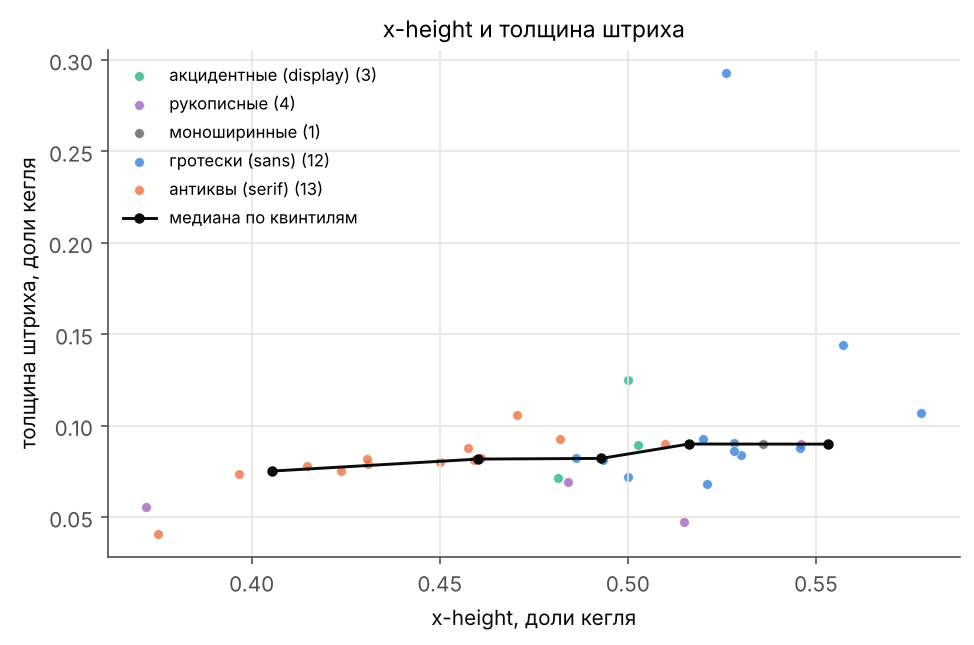

In [11]:
display(dependence.correlations(fonts.x_height, fonts.stem))
chi = dependence.chi2_independence(fonts.x_height, fonts.stem, bins=4 if len(fonts) >= 80 else 2)
perm = dependence.permutation_spearman(fonts.x_height, fonts.stem, n_perm=2000, seed=SEED)
print(f"χ² = {chi['chi2']:.1f}, df = {chi['dof']}, p = {chi['p']:.3g}, V Крамера = {chi['cramer_v']:.3f}")
print(f"перестановочный тест: ρ = {perm['rho']:.3f}, p = {perm['p']:.4f}")
print("ρ внутри категорий:", {c: round(stats.spearmanr(g.x_height, g.stem)[0], 3) for c, g in fonts.groupby("category") if len(g) >= 8})
fp.scatter_by_category(fonts, "x_height", "stem", "x-height, доли кегля", "толщина штриха, доли кегля",
                       "x-height и толщина штриха", "fonts_dependence.png");

<a id="fig7"></a>
*Рис. 7. x-height и толщина штриха; цвет — категория, чёрная линия — медиана толщины по квинтилям x-height.*

**Результаты:**

- Пирсон +0.374, Спирмен +0.576, Кендалл +0.418
  (для Спирмена $p = 0.0005$).
- $\chi^2 = 10.9$ при $\mathrm{df} = 1$, $p = 0.0009$, $V$ Крамера 0.575.
- Перестановочный тест: $\rho = +0.576$, $p = 0.0010$. $H_0$ о независимости при $\alpha = 0.05$ **отвергается**.
- $\rho$ Спирмена внутри категорий: sans +0.58, serif +0.92.

**TODO КТвД: вывод о зависимости своими словами.** _Вопросы: есть ли связь, насколько она сильна? держится ли она
внутри категорий? как это объяснить с точки зрения дизайна шрифта?_

<a id="hyp"></a>
### 4.1 Гипотеза: у гротесков x-height больше, чем у антикв

В типографике принято считать, что у гротесков строчные выше, чем у антикв. Проверяем односторонним критерием
Манна–Уитни: $H_0$: $P(X_{\text{sans}} > X_{\text{serif}}) \le 1/2$, $\alpha = 0.05$.


<sub>[↑ к содержанию](#toc)</sub>

In [12]:
sans, serif = fonts.x_height[fonts.category == "sans"], fonts.x_height[fonts.category == "serif"]
h_sans = hyp.mann_whitney(sans, serif, alternative="greater")
print(f"медиана x-height: гротески {sans.median():.3f} (n = {len(sans)}), антиквы {serif.median():.3f} (n = {len(serif)})")
pd.Series(h_sans)

медиана x-height: гротески 0.527 (n = 12), антиквы 0.450 (n = 13)


test        Mann–Whitney (greater)
H0                  P(A > B) ≤ 1/2
stat                         153.0
p                              0.0
decision              отвергаем H0
p_a_gt_b                    0.9808
dtype: object

**Результаты:** медиана x-height у гротесков 0.527, у антикв 0.450;
критерий Манна–Уитни $p \approx 10^{-5}$, $H_0$ **отвергается**.

<a id="resume"></a>
## 5. Resume

<a id="res-metrics"></a>
### 5.1 Итоговые метрики

<sub>[↑ к содержанию](#toc)</sub>

In [13]:
rows = []
for col, nm in [("x_height", "x-height"), ("stem", "толщина штриха")]:
    v = fonts[col]
    rows.append({"величина": nm, "N": len(v), "среднее": v.mean(), "СКО": v.std(), "медиана": v.median(),
                 "асимметрия": stats.skew(v), "эксцесс": stats.kurtosis(v),
                 "R² по остальным": stochastic.cv_r2_linear(full[[c for c in OTHERS + ["x_height", "stem"] if c != col]].to_numpy(), full[col].to_numpy(), k=5, seed=SEED)["r2_cv"],
                 "лучшая по AIC": dist.fit_candidates(v.to_numpy()).index[0]})
pd.DataFrame(rows).set_index("величина").round(4)

,N,среднее,СКО,медиана,асимметрия,эксцесс,R² по остальным,лучшая по AIC
величина,,,,,,,,
x-height,33,0.4852,0.0521,0.4933,-0.5126,-0.4398,-2.5987,skewnorm
толщина штриха,33,0.0901,0.0412,0.0825,3.7676,16.2853,-0.4446,lognorm


<a id="res-concl"></a>
### 5.2 Выводы

**TODO КТвД: выводы своими словами** (преподаватель просит «как на лабах по физике»).
_Вопросы: почему x-height и толщина штриха — случайные величины? какие у них распределения? зависимы ли они и
почему? что подтвердила гипотеза про гротески? какие ограничения у коллекции (не случайный отбор, мало шрифтов
в категории, Google Fonts — не все шрифты мира)?_

<a id="res-lit"></a>
### 5.3 Литература

1. Брингхерст Р. Основы стиля в типографике. М.: Д. Аронов, 2006 (Bringhurst R. The Elements of Typographic Style).
2. Королькова А. Живая типографика. М.: IndexMarket, 2007.
3. Microsoft. OpenType specification: таблицы `head` (unitsPerEm), `OS/2` (sxHeight, usWeightClass), `hmtx`, `fvar`.
4. fontTools: библиотека для работы со шрифтами на Python. github.com/fonttools/fonttools.
5. Google Fonts: каталог шрифтов с открытой лицензией (SIL OFL). fonts.google.com.

**TODO КТвД:** добавить источники из библиотек (РГБ, РНБ, ИТМО, eLibrary): за подбор литературы отдельный балл.

<a id="res-marks"></a>
### 5.4 cat_mark_table

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| КТвД: доп. датасет | [1](#ds) | | собственный датасет, собран и измерен своим скриптом |
| КТвД: случайная величина | [2.1](#rv1-desc), [3.1](#rv2-desc) | | $R^2$ по остальным измерениям и остаток против точности |
| КТвД: (не)зависимость | [4](#dep) | | корреляции, $\chi^2$, перестановочный тест, проверка внутри категорий |
| КТвД: EDA | [1.2](#ds-eda), [2.2](#rv1-eda), [3.2](#rv2-eda) | | описательные статистики, категории, подбор семейств |
| КТвД: гипотеза | [4.1](#hyp) | | гротески против антикв, Манн–Уитни |
| КТвД: оформление | [содержание](#toc) | | нумерация, якоря, скрытый код, подписи рисунков, LaTeX |


<sub>[↑ к содержанию](#toc)</sub>